<a href="https://colab.research.google.com/github/ade071212/Tugas-Modul-ML/blob/main/Tugas_Modul_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Latihan 5 – Machine Learning
## Decision Tree: Pengaruh Hyperparameter, Overfitting, dan Pruning pada Dataset Wine

## 1. Import Library dan Memuat Dataset

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

pd.set_option("display.width", 180)
SEED = 21

In [ ]:
# Dataset Wine bawaan scikit-learn (178 sampel, 13 fitur kimia, 3 jenis anggur)
wine = load_wine(as_frame=True)
df = wine.frame.copy()
nama_fitur = list(wine.feature_names)
nama_kelas = [str(k) for k in wine.target_names]

print("Ukuran data :", df.shape)
print("Nilai kosong:", int(df.isna().sum().sum()))
print("\nJumlah per kelas:")
print(df["target"].value_counts().sort_index().rename(dict(enumerate(nama_kelas))))
df.head()

Ukuran data : (178, 14)
Nilai kosong: 0

Jumlah per kelas:
target
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


## 2. Split Data Terstratifikasi (75 : 25)

In [ ]:
X = df[nama_fitur]
y = df["target"]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)

print(f"Data latih: {len(X_tr)} | Data uji: {len(X_te)}")
print("\nProporsi tiap kelas:")
print(pd.DataFrame({"semua": y.value_counts(normalize=True).sort_index(),
                    "latih": y_tr.value_counts(normalize=True).sort_index(),
                    "uji":   y_te.value_counts(normalize=True).sort_index()}).round(3))

Data latih: 133 | Data uji: 45

Proporsi tiap kelas:
        semua  latih    uji
target                     
0       0.331  0.331  0.333
1       0.399  0.398  0.400
2       0.270  0.271  0.267


## 3. Eksperimen Hyperparameter: max_depth × min_samples_leaf

In [ ]:
daftar_depth = [1, 2, 3, 5, None]
daftar_leaf = [1, 3, 8]

lipat = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
catatan = []

for depth in daftar_depth:
    for leaf in daftar_leaf:
        pohon = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=SEED)
        skor_cv = cross_val_score(pohon, X_tr, y_tr, cv=lipat)
        pohon.fit(X_tr, y_tr)
        a_latih = pohon.score(X_tr, y_tr)
        a_uji = pohon.score(X_te, y_te)
        catatan.append({
            "depth": "None" if depth is None else depth,
            "leaf_min": leaf,
            "train": a_latih, "cv": skor_cv.mean(), "cv_std": skor_cv.std(),
            "test": a_uji, "gap": a_latih - a_uji,
            "jml_daun": pohon.get_n_leaves(), "depth_nyata": pohon.get_depth()})

eksperimen = pd.DataFrame(catatan)
print(f"Total kombinasi: {len(eksperimen)}")
eksperimen.round(4)

Total kombinasi: 15


,depth,leaf_min,train,cv,cv_std,test,gap,jml_daun,depth_nyata
0,1,1,0.6992,0.5490,0.0396,0.6889,0.0104,2,1
1,1,3,0.6992,0.5490,0.0396,0.6889,0.0104,2,1
2,1,8,0.6992,0.5490,0.0396,0.6889,0.0104,2,1
3,2,1,0.9474,0.8271,0.0609,0.8222,0.1251,4,2
4,2,3,0.9474,0.8271,0.0609,0.8222,0.1251,4,2
5,2,8,0.9398,0.8271,0.0609,0.8222,0.1176,4,2
6,3,1,0.9925,0.9028,0.0728,0.8444,0.1480,8,3
7,3,3,0.9774,0.8880,0.0741,0.8444,0.1330,8,3
8,3,8,0.9398,0.8578,0.0716,0.8222,0.1176,6,3
9,5,1,1.0000,0.9103,0.0506,0.8444,0.1556,9,4


## 4. Membandingkan Train, CV, dan Test

In [ ]:
urut = eksperimen.sort_values(["cv", "jml_daun"], ascending=[False, True]).reset_index(drop=True)
urut.index += 1
urut[["depth", "leaf_min", "train", "cv", "test", "gap", "jml_daun"]].round(4)

,depth,leaf_min,train,cv,test,gap,jml_daun
1,5,1,1.0000,0.9103,0.8444,0.1556,9
2,None,1,1.0000,0.9103,0.8444,0.1556,9
3,3,1,0.9925,0.9028,0.8444,0.1480,8
4,3,3,0.9774,0.8880,0.8444,0.1330,8
5,5,3,0.9774,0.8880,0.8444,0.1330,8
6,None,3,0.9774,0.8880,0.8444,0.1330,8
7,3,8,0.9398,0.8578,0.8222,0.1176,6
8,5,8,0.9398,0.8578,0.8222,0.1176,6
9,None,8,0.9398,0.8578,0.8222,0.1176,6
10,2,1,0.9474,0.8271,0.8222,0.1251,4


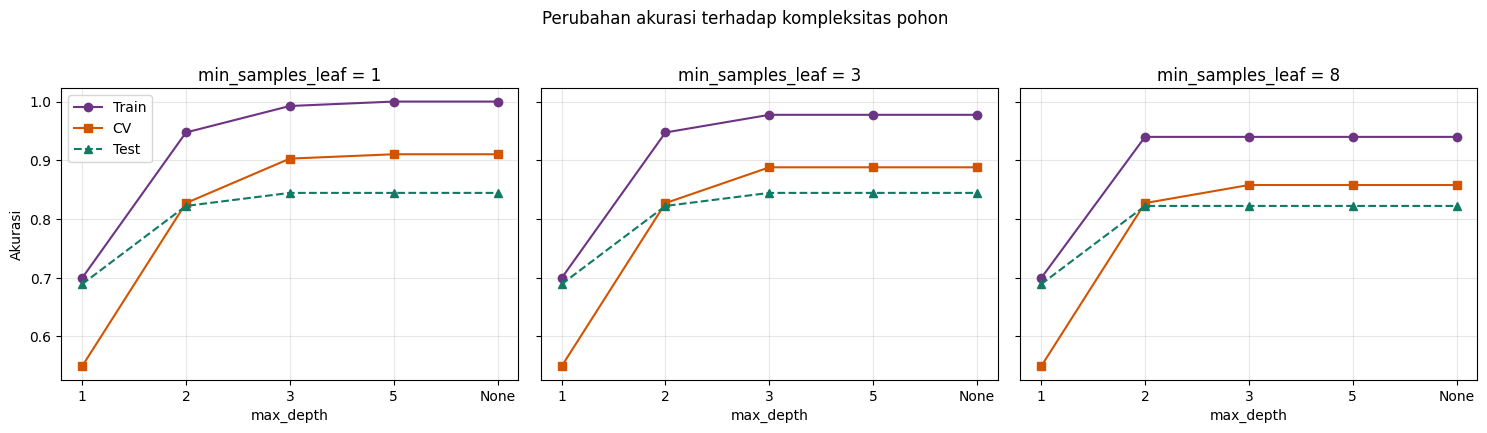

In [ ]:
fig, axs = plt.subplots(1, len(daftar_leaf), figsize=(15, 4.2), sharey=True)
label_depth = [str(d) for d in daftar_depth]

for ax, leaf in zip(axs, daftar_leaf):
    sub = eksperimen[eksperimen["leaf_min"] == leaf].copy()
    sub["depth"] = sub["depth"].astype(str)
    sub = sub.set_index("depth").loc[label_depth]
    ax.plot(label_depth, sub["train"], marker="o", label="Train", color="#6c3483")
    ax.plot(label_depth, sub["cv"], marker="s", label="CV", color="#d35400")
    ax.plot(label_depth, sub["test"], marker="^", linestyle="--", label="Test", color="#117a65")
    ax.set_title(f"min_samples_leaf = {leaf}")
    ax.set_xlabel("max_depth")
    ax.grid(alpha=0.3)
axs[0].set_ylabel("Akurasi")
axs[0].legend()
plt.suptitle("Perubahan akurasi terhadap kompleksitas pohon", y=1.02)
plt.tight_layout()
plt.show()

## 5. Memilih Model Terbaik (berdasarkan CV)

In [ ]:
pilih = urut.iloc[0]
depth_pilih = None if pilih["depth"] == "None" else int(pilih["depth"])
leaf_pilih = int(pilih["leaf_min"])

print("Kriteria: akurasi CV tertinggi; jika seri, pohon dengan daun paling sedikit.")
print(f"max_depth        = {depth_pilih}")
print(f"min_samples_leaf = {leaf_pilih}")
print(f"Akurasi CV       = {pilih['cv']:.4f} (std {pilih['cv_std']:.4f})")

Kriteria: akurasi CV tertinggi; jika seri, pohon dengan daun paling sedikit.
max_depth        = 5
min_samples_leaf = 1
Akurasi CV       = 0.9103 (std 0.0506)


## 6. Evaluasi Model Terpilih pada Data Uji

In [ ]:
pohon_akhir = DecisionTreeClassifier(max_depth=depth_pilih, min_samples_leaf=leaf_pilih,
                                     random_state=SEED).fit(X_tr, y_tr)

pred = pohon_akhir.predict(X_te)
a_latih = pohon_akhir.score(X_tr, y_tr)
a_cv = cross_val_score(pohon_akhir, X_tr, y_tr, cv=lipat).mean()
a_uji = accuracy_score(y_te, pred)
f1_makro = f1_score(y_te, pred, average="macro")

ringkas = pd.Series({
    "max_depth": depth_pilih, "min_samples_leaf": leaf_pilih,
    "Akurasi latih": round(a_latih, 4), "Akurasi CV": round(a_cv, 4),
    "Akurasi uji": round(a_uji, 4), "F1 makro (uji)": round(f1_makro, 4),
    "Selisih latih-uji": round(a_latih - a_uji, 4),
    "Jumlah daun": pohon_akhir.get_n_leaves(), "Kedalaman nyata": pohon_akhir.get_depth()},
    name="Nilai")
ringkas.to_frame()

,Nilai
max_depth,5.0000
min_samples_leaf,1.0000
Akurasi latih,1.0000
Akurasi CV,0.9103
Akurasi uji,0.8444
F1 makro (uji),0.8444
Selisih latih-uji,0.1556
Jumlah daun,9.0000
Kedalaman nyata,4.0000


              precision    recall  f1-score   support

     class_0      0.933     0.933     0.933        15
     class_1      0.824     0.778     0.800        18
     class_2      0.769     0.833     0.800        12

    accuracy                          0.844        45
   macro avg      0.842     0.848     0.844        45
weighted avg      0.846     0.844     0.844        45



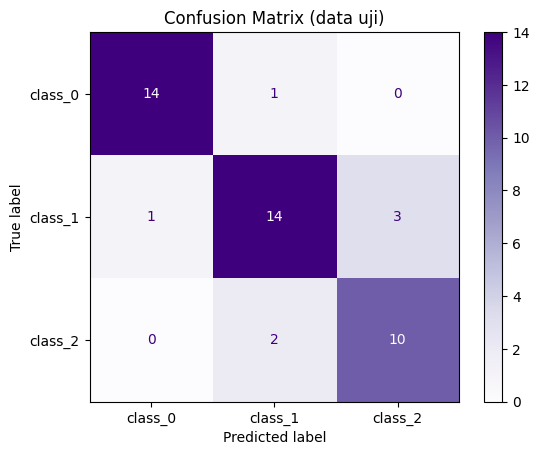

In [ ]:
print(classification_report(y_te, pred, target_names=nama_kelas, digits=3))

ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=nama_kelas, cmap="Purples")
plt.title("Confusion Matrix (data uji)")
plt.show()

## 7. Visualisasi dan Interpretasi Pohon

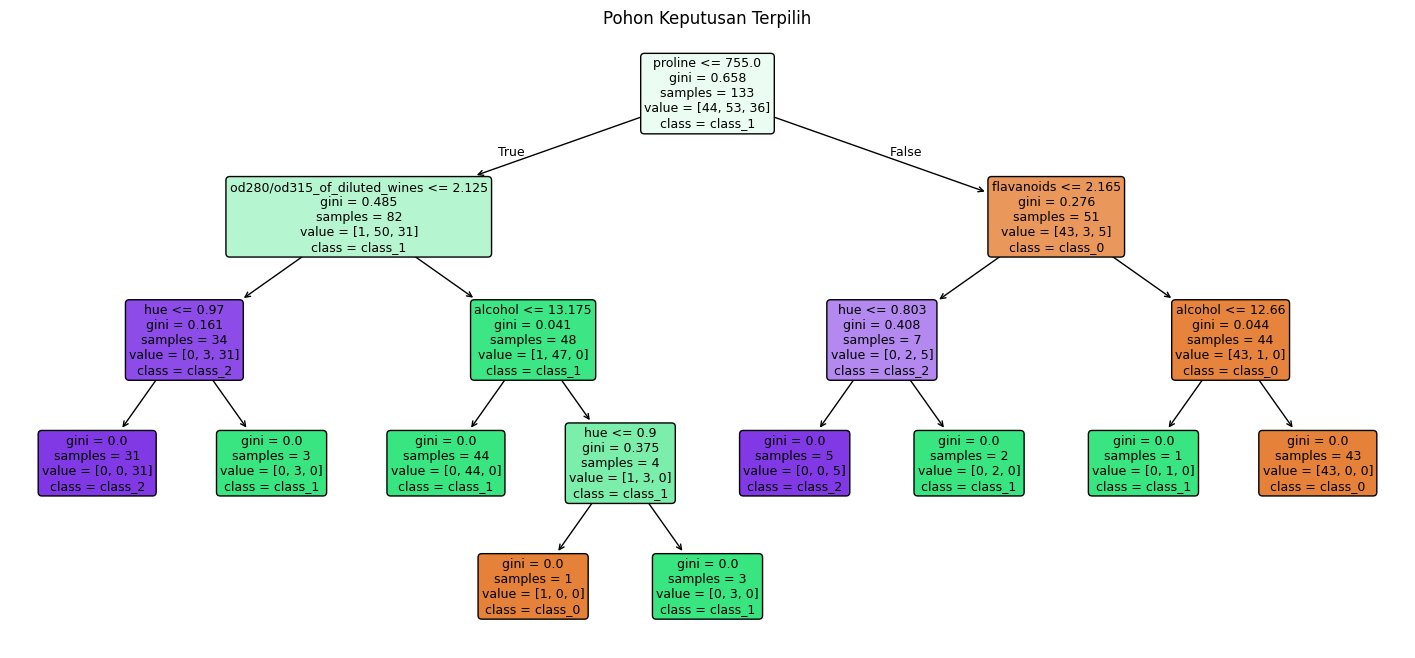

In [ ]:
plt.figure(figsize=(18, 8))
plot_tree(pohon_akhir, feature_names=nama_fitur, class_names=nama_kelas,
          filled=True, rounded=True, fontsize=9)
plt.title("Pohon Keputusan Terpilih")
plt.show()

In [ ]:
print(export_text(pohon_akhir, feature_names=nama_fitur))

|--- proline <= 755.00
|   |--- od280/od315_of_diluted_wines <= 2.12
|   |   |--- hue <= 0.97
|   |   |   |--- class: 2
|   |   |--- hue >  0.97
|   |   |   |--- class: 1
|   |--- od280/od315_of_diluted_wines >  2.12
|   |   |--- alcohol <= 13.17
|   |   |   |--- class: 1
|   |   |--- alcohol >  13.17
|   |   |   |--- hue <= 0.90
|   |   |   |   |--- class: 0
|   |   |   |--- hue >  0.90
|   |   |   |   |--- class: 1
|--- proline >  755.00
|   |--- flavanoids <= 2.17
|   |   |--- hue <= 0.80
|   |   |   |--- class: 2
|   |   |--- hue >  0.80
|   |   |   |--- class: 1
|   |--- flavanoids >  2.17
|   |   |--- alcohol <= 12.66
|   |   |   |--- class: 1
|   |   |--- alcohol >  12.66
|   |   |   |--- class: 0



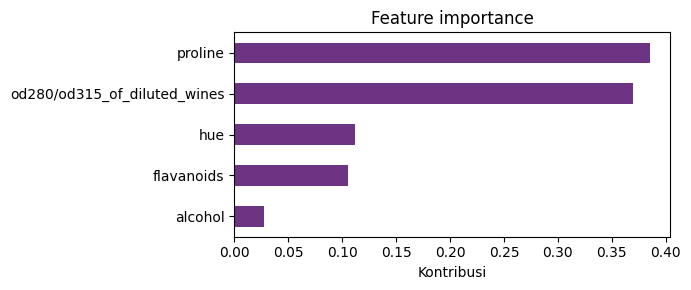

In [ ]:
penting = pd.Series(pohon_akhir.feature_importances_, index=nama_fitur)
penting = penting[penting > 0].sort_values()

penting.plot(kind="barh", figsize=(7, max(3, 0.45 * len(penting))), color="#6c3483")
plt.title("Feature importance")
plt.xlabel("Kontribusi")
plt.tight_layout()
plt.show()

## 8. Pohon Tanpa Batas vs Pohon Dibatasi

In [ ]:
pembanding = {
    "Tanpa batas": DecisionTreeClassifier(random_state=SEED),
    "Dibatasi (depth=3, leaf=3)": DecisionTreeClassifier(max_depth=3, min_samples_leaf=3, random_state=SEED)}

baris = []
for judul, mdl in pembanding.items():
    mdl.fit(X_tr, y_tr)
    tr, te = mdl.score(X_tr, y_tr), mdl.score(X_te, y_te)
    baris.append({"Model": judul, "Train": tr, "Test": te, "Gap": tr - te,
                  "Kedalaman": mdl.get_depth(), "Jumlah daun": mdl.get_n_leaves()})
pd.DataFrame(baris).round(4)

,Model,Train,Test,Gap,Kedalaman,Jumlah daun
0,Tanpa batas,1.0000,0.8444,0.1556,4,9
1,"Dibatasi (depth=3, leaf=3)",0.9774,0.8444,0.1330,3,8


## 9. Post-Pruning dengan Cost-Complexity (ccp_alpha)

In [ ]:
jalur = DecisionTreeClassifier(random_state=SEED).cost_complexity_pruning_path(X_tr, y_tr)
kandidat_alpha = np.unique(jalur.ccp_alphas.round(5))

hasil_alpha = []
for a in kandidat_alpha:
    mdl = DecisionTreeClassifier(ccp_alpha=a, random_state=SEED)
    hasil_alpha.append({
        "alpha": a,
        "cv": cross_val_score(mdl, X_tr, y_tr, cv=lipat).mean(),
        "train": mdl.fit(X_tr, y_tr).score(X_tr, y_tr),
        "daun": mdl.get_n_leaves()})
tab_alpha = pd.DataFrame(hasil_alpha)

# jika CV seri, ambil alpha terbesar (pohon paling sederhana)
maks = tab_alpha["cv"].max()
alpha_pilih = tab_alpha[tab_alpha["cv"] == maks]["alpha"].max()
baris_pilih = tab_alpha[tab_alpha["alpha"] == alpha_pilih].iloc[0]
print(f"alpha terbaik: {alpha_pilih} | CV = {baris_pilih['cv']:.4f} | daun = {int(baris_pilih['daun'])}")

alpha terbaik: 0.02148 | CV = 0.9177 | daun = 6


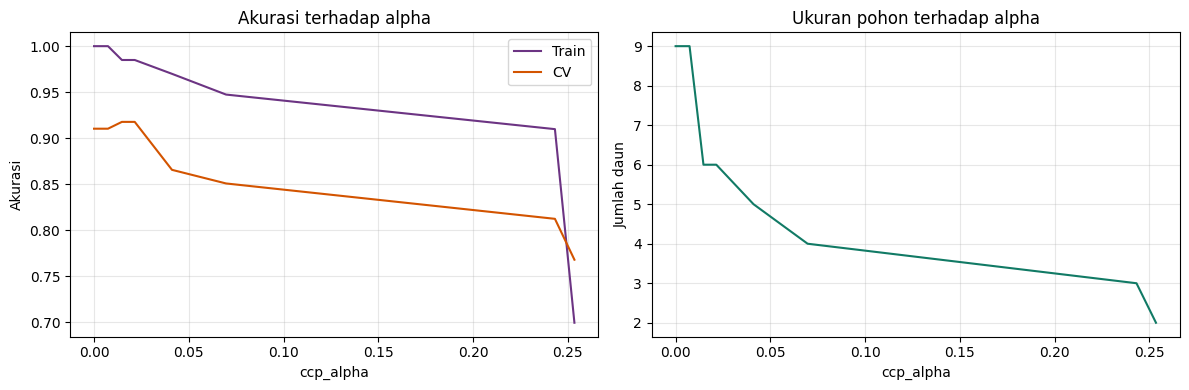

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(tab_alpha["alpha"], tab_alpha["train"], label="Train", color="#6c3483")
axs[0].plot(tab_alpha["alpha"], tab_alpha["cv"], label="CV", color="#d35400")
axs[0].set(xlabel="ccp_alpha", ylabel="Akurasi", title="Akurasi terhadap alpha")
axs[0].legend(); axs[0].grid(alpha=0.3)

axs[1].plot(tab_alpha["alpha"], tab_alpha["daun"], color="#117a65")
axs[1].set(xlabel="ccp_alpha", ylabel="Jumlah daun", title="Ukuran pohon terhadap alpha")
axs[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Kesimpulan

In [ ]:
puncak_train = eksperimen.sort_values(["train", "jml_daun"], ascending=[False, False]).iloc[0]
sama = (str(puncak_train["depth"]) == str(depth_pilih)) and (int(puncak_train["leaf_min"]) == leaf_pilih)
penuh, batas = baris[0], baris[1]

print("KESIMPULAN")
print("=" * 62)
print(f"1. Pohon dengan akurasi latih tertinggi: depth={puncak_train['depth']}, "
      f"leaf_min={puncak_train['leaf_min']} (train {puncak_train['train']:.3f}, "
      f"CV {puncak_train['cv']:.3f}, test {puncak_train['test']:.3f}).")
print(f"2. Pohon terpilih berdasarkan CV: depth={depth_pilih}, leaf_min={leaf_pilih} "
      f"(train {a_latih:.3f}, CV {a_cv:.3f}, test {a_uji:.3f}, daun {pohon_akhir.get_n_leaves()}).")
if sama:
    print("   Pada percobaan ini keduanya sama, jadi akurasi latih tertinggi juga")
    print("   menghasilkan CV tertinggi pada kombinasi yang diuji.")
print(f"3. Pohon tanpa batas: train {penuh['Train']:.3f}, test {penuh['Test']:.3f}, "
      f"gap {penuh['Gap']:.3f}, daun {penuh['Jumlah daun']}.")
print(f"   Pohon dibatasi    : train {batas['Train']:.3f}, test {batas['Test']:.3f}, "
      f"gap {batas['Gap']:.3f}, daun {batas['Jumlah daun']}.")
print(f"4. Pruning ccp_alpha={alpha_pilih} menghasilkan {int(baris_pilih['daun'])} daun dengan "
      f"CV {baris_pilih['cv']:.3f}, yaitu pohon lebih kecil dengan akurasi CV yang sebanding.")
print("5. Akurasi latih mendekati 1,0 belum berarti model terbaik. Pembanding yang adil")
print("   adalah CV dan test; selisih besar antara latih dan test menandakan overfitting.")
print("6. Pemilihan model memakai CV pada data latih, bukan data uji, agar data uji")
print("   tetap menjadi penilaian akhir yang objektif.")

KESIMPULAN
1. Pohon dengan akurasi latih tertinggi: depth=5, leaf_min=1 (train 1.000, CV 0.910, test 0.844).
2. Pohon terpilih berdasarkan CV: depth=5, leaf_min=1 (train 1.000, CV 0.910, test 0.844, daun 9).
   Pada percobaan ini keduanya sama, jadi akurasi latih tertinggi juga
   menghasilkan CV tertinggi pada kombinasi yang diuji.
3. Pohon tanpa batas: train 1.000, test 0.844, gap 0.156, daun 9.
   Pohon dibatasi    : train 0.977, test 0.844, gap 0.133, daun 8.
4. Pruning ccp_alpha=0.02148 menghasilkan 6 daun dengan CV 0.918, yaitu pohon lebih kecil dengan akurasi CV yang sebanding.
5. Akurasi latih mendekati 1,0 belum berarti model terbaik. Pembanding yang adil
   adalah CV dan test; selisih besar antara latih dan test menandakan overfitting.
6. Pemilihan model memakai CV pada data latih, bukan data uji, agar data uji
   tetap menjadi penilaian akhir yang objektif.
